# Data Analyst Salary Benchmarking
### Data Cleaning and Feature Engineering for a Salary Prediction Model
*A DataBridge hiring case study using 2,253 Glassdoor job postings*

---


## 📌 Introduction
---
*This is a hypothetical case study developed for portfolio purposes.*

### Business Context:

Four years after founding DataBridge, a remote IT consulting startup in Texas, Maria Cruz has secured a new healthcare contract. To meet its demands, she needs to hire **eight Junior and two Senior Data Analysts** skilled in Tableau, Python, and SQL.

However, DataBridge has no established salary bands. Relying on intuition to determine compensation makes it difficult to balance competitive offers with the company's budget.

As DataBridge's Data Analyst, my task is to help Maria make evidence-based compensation decisions using **2,253 raw Glassdoor job postings**.




### Objective:

Before investigating salary patterns or building a predictive model, I must ensure the data is reliable and suitable for analysis. The raw dataset contains inconsistent formats, numerical information stored as text, missing values represented by `-1` placeholders, and unstructured text containing information about job seniority and technical skills.

This notebook focuses on **data profiling, cleaning, and preparation**. I will assess data quality, standardize and transform fields, engineer relevant features, handle missing values, and prepare categorical variables for subsequent analysis and modeling.

The outcome will be a clean, structured dataset ready for the next stage: **exploratory data analysis (EDA)**, followed by regression modeling to assess whether the data can support salary recommendations for DataBridge.

## 📋 Data Cleaning Summary
---


After profiling the dataset, I took the following actions:

1. **Standardization and quality checks**
   - Standardized column names to lowercase with underscores.
   - Converted `-1` placeholders to true nulls.
   - Checked for duplicates on full rows and column subsets; none were found.
2. **Scope filtering**
   - Kept only the columns needed and filtered rows to Data Analyst postings using regex.
3. **Data type parsing**
   - Used regex to convert salary estimate, revenue, and company size from text to numeric values, creating minimum, maximum, and median salary columns.
4. **Feature engineering**
   - Built a Natural Language Processing text cleaning pipeline for job titles and descriptions.
   - Created role tier (junior, mid, senior) and extracted technical skills, with a binary column for each role tier and each skill.
   - Created state and cost of living features (U.S. News & World Report, n.d.).
   - Grouped company size using OECD classes (OECD, n.d.).
### 5. Missing Values
- **Removed rows with minimal missing data:** Dropped rows containing missing values in columns with 5% or less missing data.
- **Categorical imputation:** Filled missing values in categorical columns using the mode (the most frequently occurring category).
- **Company size group imputation:** Estimated missing `company_size_group` values by comparing each company's revenue against the 25th–75th percentile revenue ranges of medium and large companies. Assigned a company size group when its revenue fell within the corresponding range.
- **Numerical imputation:** Filled missing values in `rating` and `revenue` using the median of their respective company size groups to account for differences in company scale.

**AI disclosure:** I used AI only to assist with dictionary structures and a few loops, then reviewed, edited, and refined them myself.

---

### References

OECD. (n.d.). *Enterprises by business size*. https://www.oecd.org/en/data/indicators/enterprises-by-business-size.html

U.S. News & World Report. (n.d.). *Cost of living*. In *Best States rankings: Opportunity – Affordability*. https://www.usnews.com/news/best-states/rankings/opportunity/affordability/cost-living

---

##⚙️ The Data Cleaning Pipeline
---

### 1. Import libraries and upload the data set

In [389]:
# Import necessary modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import regex as re
import seaborn as sns
import nltk
import string

In [390]:
from google.colab import files

In [391]:
# Upload the file
df = files.upload()


Saving glassdoor_jobs.csv to glassdoor_jobs.csv


In [392]:
# Check the dataframe
df = pd.read_csv("glassdoor_jobs.csv")
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY","New York, NY",201 to 500 employees,1961,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),-1,True
1,1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY","New York, NY",10000+ employees,1893,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1,-1
2,2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY","New York, NY",1001 to 5000 employees,2003,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,GoDaddy,-1
3,3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY","McLean, VA",201 to 500 employees,2002,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),-1,-1
4,4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY","New York, NY",501 to 1000 employees,2009,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),DraftKings,True



### 2. Data profiling:




#### **2.1 Data shape**

In [393]:
# Check the data shape
df.shape

(2253, 16)

##### **📸 Data Cleaning Snapshot - Raw Data**

In [394]:
# Data cleaning snap shot (Raw Data)
raw_rows, raw_cols = df.shape


#### **2.2 Data type**

Observations:
- Column names should be standardized into lower case with underscore delimeters.
 - Columns with object data types should be converted into its proper type.

In [395]:
# Check the datatype for each column, and whether there are missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2253 entries, 0 to 2252
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         2253 non-null   int64  
 1   Job Title          2253 non-null   object 
 2   Salary Estimate    2253 non-null   object 
 3   Job Description    2253 non-null   object 
 4   Rating             2253 non-null   float64
 5   Company Name       2252 non-null   object 
 6   Location           2253 non-null   object 
 7   Headquarters       2253 non-null   object 
 8   Size               2253 non-null   object 
 9   Founded            2253 non-null   int64  
 10  Type of ownership  2253 non-null   object 
 11  Industry           2253 non-null   object 
 12  Sector             2253 non-null   object 
 13  Revenue            2253 non-null   object 
 14  Competitors        2253 non-null   object 
 15  Easy Apply         2253 non-null   object 
dtypes: float64(1), int64(2),

#### **2.3 Null values**

In [396]:
# Check null values
df.isna().sum()

,0
Unnamed: 0,0
Job Title,0
Salary Estimate,0
Job Description,0
Rating,0
Company Name,1
Location,0
Headquarters,0
Size,0
Founded,0


#### **2.4 Data inconsistencies**

Observations:

- The **'Salary Estimate' & 'Size' Columns** are in text format which should be parsed and converted into numerical values.
- **'Competitors'** and **'Easy Apply' Columns** have -1 values which indicate missing or unknown data.
- In the **'Job Title' Column**, the values should be parsed into consistent seniority labels such as "Junior", "Senior", and "Mid
- The **'Size', 'Type of Ownership', 'Sector', and 'Revenue' Columns** also contain -1 values.



In [397]:
# Checks the first five rows to observe data inconsistencies.
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY","New York, NY",201 to 500 employees,1961,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),-1,True
1,1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY","New York, NY",10000+ employees,1893,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1,-1
2,2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY","New York, NY",1001 to 5000 employees,2003,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,GoDaddy,-1
3,3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY","McLean, VA",201 to 500 employees,2002,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),-1,-1
4,4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY","New York, NY",501 to 1000 employees,2009,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),DraftKings,True


In [398]:
# Check the last five rows
df.tail()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
2248,2248,RQS - IHHA - 201900004460 -1q Data Security An...,$78K-$104K (Glassdoor est.),Maintains systems to protect data from unautho...,2.5,"Avacend, Inc.\n2.5","Denver, CO","Alpharetta, GA",51 to 200 employees,-1,Company - Private,Staffing & Outsourcing,Business Services,Unknown / Non-Applicable,-1,-1
2249,2249,Senior Data Analyst (Corporate Audit),$78K-$104K (Glassdoor est.),Position:\nSenior Data Analyst (Corporate Audi...,2.9,Arrow Electronics\n2.9,"Centennial, CO","Centennial, CO",10000+ employees,1935,Company - Public,Wholesale,Business Services,$10+ billion (USD),"Avnet, Ingram Micro, Tech Data",-1
2250,2250,"Technical Business Analyst (SQL, Data analytic...",$78K-$104K (Glassdoor est.),"Title: Technical Business Analyst (SQL, Data a...",-1.0,Spiceorb,"Denver, CO",-1,-1,-1,-1,-1,-1,-1,-1,-1
2251,2251,"Data Analyst 3, Customer Experience",$78K-$104K (Glassdoor est.),Summary\n\nResponsible for working cross-funct...,3.1,Contingent Network Services\n3.1,"Centennial, CO","West Chester, OH",201 to 500 employees,1984,Company - Private,Enterprise Software & Network Solutions,Information Technology,$25 to $50 million (USD),-1,-1
2252,2252,Senior Quality Data Analyst,$78K-$104K (Glassdoor est.),"You.\n\nYou bring your body, mind, heart and s...",3.4,SCL Health\n3.4,"Broomfield, CO","Broomfield, CO",10000+ employees,1864,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),"Centura Health, HealthONE, Denver Health and H...",-1


#### **2.5 Duplicates**

In [399]:
# Check duplicates
df.duplicated().sum()

np.int64(0)

In [400]:
# Check columns for reference in checking duplicates by subsets
df.columns

Index(['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply'],
      dtype='object')

In [401]:
# Check duplicates by a subset
df[df.duplicated(subset = ['Job Title', 'Salary Estimate', 'Job Description', 'Rating',
                           'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
                           'Type of ownership', 'Industry', 'Sector', 'Revenue'])]

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply


#### **2.6 Data distribtution**


In [402]:
# Chack the statistical summary of all columns
df.describe()

,Unnamed: 0,Rating,Founded
count,2253.0000,2253.000000,2253.000000
mean,1126.0000,3.160630,1398.522858
std,650.5294,1.665228,901.929251
min,0.0000,-1.000000,-1.000000
25%,563.0000,3.100000,-1.000000
50%,1126.0000,3.600000,1979.000000
75%,1689.0000,4.000000,2002.000000
max,2252.0000,5.000000,2019.000000


In [403]:
# Check the data types
df.dtypes

,0
Unnamed: 0,int64
Job Title,object
Salary Estimate,object
Job Description,object
Rating,float64
Company Name,object
Location,object
Headquarters,object
Size,object
Founded,int64


**Observations:**
- Only **Unnamed, Rating, and Founded Columns** have numerical values.
- The **Founded Column** is not necessary for the scope of the analysis.


---


### 3. Initial data cleaning:




#### Steps:
1. Standardize column names
2. Replace -1 values into missing values (NaN)
3. Parse the **Job Title, Salary Estimate, Company Size** , and **Job Description** values
4. Convert data values into their proper data types
5. Check again for duplicates
6. Check the data's range and distribution

#### **3.1 Create a new dataframe for cleaning**

##### **Select only relavant columns for the analysis**
Four columns excluded:
- Easy Apply
- Competitors
- Headquarters
- Founded


In [404]:
df.columns

Index(['Unnamed: 0', 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Headquarters', 'Size', 'Founded',
       'Type of ownership', 'Industry', 'Sector', 'Revenue', 'Competitors',
       'Easy Apply'],
      dtype='object')

In [405]:
# Create a copy of a dataframe and assign it a name 'df_new'
df_new = df.copy()

# Pick only relevant columns for the analysis
df_new = df_new[[ 'Job Title', 'Salary Estimate', 'Job Description',
       'Rating', 'Company Name', 'Location', 'Size',
       'Type of ownership', 'Industry', 'Sector', 'Revenue' ]]



In [406]:
# Change the name of the unnamed:_0 index  with the name 'index'
df_new.index.name = 'index'
df_new.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Size,Type of ownership,Industry,Sector,Revenue
index,,,,,,,,,,,
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD)
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD)
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD)
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD)


##### 📸 **Data Cleaning Snapshot - Filtered Columns**

In [407]:
# Data cleaning snapshot
selected_cols = len(df_new.columns)
selected_cols

11

#### **3.2 Standardize column names**

In [408]:
# Normalize column names by setting them into lowercase and replacing the white spaces with underscores.
df_new.columns.str.replace(' ', '_')
df_new.columns = df_new.columns.str.replace(' ', '_')
df_new.columns = df_new.columns.str.lower()
df_new.head()

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue
index,,,,,,,,,,,
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD)
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD)
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD)
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD)


In [409]:
df_new.columns #check columns

Index(['job_title', 'salary_estimate', 'job_description', 'rating',
       'company_name', 'location', 'size', 'type_of_ownership', 'industry',
       'sector', 'revenue'],
      dtype='object')

#### **3.3 Missing values: -1**

In [410]:
# Check if there are null values fisrt in each column.
# There is one null value in the 'company_name' column.
df_new.isna().sum()

,0
job_title,0
salary_estimate,0
job_description,0
rating,0
company_name,1
location,0
size,0
type_of_ownership,0
industry,0
sector,0


**Count the occurence of -1 across columns**

In [411]:
import numpy as np
#Count the occurence of -1 values across columns.

# Initialize a dictionary to store the counts of -1 or '-1' for each column
specific_negative_one_counts = {}

# Iterate through each column
for col in df_new.columns:
    count = 0
    # Check if the column is numeric (int, float)
    if pd.api.types.is_numeric_dtype(df_new[col]):
        # Count integer -1 values, which also catches float -1.0
        count = (df_new[col] == -1).sum()
    # Check if the column is an object (typically strings or mixed types)
    elif df_new[col].dtype == 'object':
        # Count string '-1' values
        count = (df_new[col] == '-1').sum()
    specific_negative_one_counts[col] = count

# Convert the dictionary to a Pandas Series for better display
specific_negative_one_counts_series = pd.Series(specific_negative_one_counts)

specific_negative_one_counts_series

,0
job_title,0
salary_estimate,1
job_description,0
rating,272
company_name,0
location,0
size,163
type_of_ownership,163
industry,353
sector,353


##### **📸 Data cleaning snapshot (-1 null values)**

In [412]:
##### Data cleaning snapshot (-1 null values)

# Use the element-wise bitwise OR operator '|' instead of 'or'
placeholder_counts = ((df_new == -1) | (df_new == '-1')).sum()  # -1 placeholders per column
placeholder_counts = placeholder_counts[placeholder_counts > 0]
placeholder_counts.name = 'Placeholder Count'
placeholder_counts

,Placeholder Count
salary_estimate,1
rating,272
size,163
type_of_ownership,163
industry,353
sector,353
revenue,163


**Replace -1 with null values**

In [413]:
# Replace -1 values with NaN in the DataFrame
for col in df_new.columns:
    # If the column is numeric, replace integer -1
    if pd.api.types.is_numeric_dtype(df_new[col]):
        df_new[col] = df_new[col].replace(-1, np.nan)
    # If the column is object type, replace string '-1'
    elif df_new[col].dtype == 'object':
        df_new[col] = df_new[col].replace('-1', np.nan)

# Count the NaN values in each column after replacement
nan_counts_after_replacement = df_new.isna().sum()

print("NaN counts after replacing -1 values:")
print(nan_counts_after_replacement)

NaN counts after replacing -1 values:
job_title              0
salary_estimate        1
job_description        0
rating               272
company_name           1
location               0
size                 163
type_of_ownership    163
industry             353
sector               353
revenue              163
dtype: int64


In [414]:
#For the company_name column, there is 1 NaN which was already present in the original dataset and was not a -1 value.
df_new.isna().sum()

,0
job_title,0
salary_estimate,1
job_description,0
rating,272
company_name,1
location,0
size,163
type_of_ownership,163
industry,353
sector,353



### 4. Data preprocessing:

#### **4.1 Text cleaning pipeline**

In [415]:
# ---PACKAGES---

# - For stopwords
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english')) # Removes duplicates from the stopwords list

# - For punctuations
import re
import string

# - For tokenization
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')





#---HELPER FUNCTIONS---

# _Remove Stopwords

def _remove_stopwords(tokenized_line: str) -> list:
  '''
  Iterates over tokens in a line to filter out stop words.
  Returns a list of tokens with no stop words.
  '''
  not_stop_word_tokens = [word for word in tokenized_line if word not in stop_words]
  return not_stop_word_tokens



# _Remove Punctuation Marks

def _remove_punctuations(text: str) -> str:
    '''
    Accesses the string of punctuations from the string module.
    Uses the escape function to turn each punctuation mark to a string literal.
    Creates a new punctuation list suitable for regex pattern matching.
    Loops through each text and replaces its punctuation marks with an empty string.
    Returns cleaned texts with no punctuation marks.
    '''
    _re_punctuation = '|'.join(
        [
        re.escape(mark)
        for mark in string.punctuation
        ]
        )

    return re.sub(_re_punctuation, '', text)



# ---MAIN FUNCTION---


# Create a clean-text function
def clean_text(row: str) -> list:
  '''
  Works as a lambda function to clean texts in a column.
  Takes a column input for removing punctuations and stop words.
  Returns a clean list of tokens per row.
  '''
  # Split each text into lines
  split_lines = [line.lower() for line in row.splitlines() if len(line) > 0]

  # Remove punctuations by line and convert to series
  no_punct_lines = [_remove_punctuations(line) for line in split_lines]


  # Convert list lines to strings before word tokenization
  joined_lines = [' '.join(no_punct_lines)]


  # Tokenize lines by word
  tokenized_lines = [word_tokenize(row) for row in joined_lines]

  # Remove stop words
  no_stop_tokens = [ _remove_stopwords(line) for line in tokenized_lines ]


  # Remove/filter out special characters by token
  no_punct_tokens = [ tok
                     for line in no_stop_tokens
                      for tok in line
                      if re.fullmatch(r'\w+', tok)
                      if len(tok) > 0
                      ]

  return no_punct_tokens






[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


#### **4.2 Filter for data analyst jobs**

#####  **Apply the text cleaning pipeline on the 'job_title' column**

In [416]:
# Apply the text cleaning pipeline to the job title column
raw_title = df_new['job_title']

# Ensure the input is joined to a raw string if it is stored as a list
clean_job_title = raw_title.apply(lambda x: clean_text(' '.join(x) if isinstance(x, list) else str(x)))
joined_job_title = clean_job_title.apply(lambda x: ' '.join(x))

# Add the cleaned job title column to the dataframe
df_new['cleaned_job_title'] = joined_job_title


In [417]:
# Create a loop that iterates through the joined job title to filter for only data analyst not bi or business analyst
valid_indices = []

for index, title in joined_job_title.items():
    title_lower = str(title).lower()
    # Check if 'data analyst' (allowing for spacing) is present
    has_data_analyst = re.search(r'\bdata\s?analyst\b', title_lower) is not None
    # Check if 'business analyst' or 'bi analyst' is present
    has_business_analyst = re.search(r'\b(business|bi)\s?analyst\b', title_lower) is not None

    if has_data_analyst and not has_business_analyst:
        valid_indices.append(index)

# Filter df_new using the valid indices from our loop
df_new = df_new.loc[df_new.index.intersection(valid_indices)]
df_new.head()


,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title
index,,,,,,,,,,,,
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst


In [418]:
# Reset the index of the dataframe and explicitly drop both the un-named index and the column named 'index'
df_new = df_new.reset_index(drop=True)
if 'index' in df_new.columns:
    df_new = df_new.drop(columns=['index'])

# Display the updated dataframe
df_new.head()

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst


##### 📸 **Data Cleaning Snapshot - Filtered Rows**

In [419]:
# Data Cleaning Snapshot (Data Analyst Filter)
rows_after_filter = df_new.shape[0]
rows_after_filter

1557

##### **Apply the text cleaning pipeline on the 'job_description' column**


In [420]:
# Assign the job description column to the 'job_desc_col' variable first for code testing.

job_desc_col = df_new['job_description']
job_desc_col

,job_description
0,Are you eager to roll up your sleeves and harn...
1,Overview\n\nProvides analytical and technical ...
2,We’re looking for a Senior Data Analyst who ha...
3,Requisition NumberRR-0001939\nRemote:Yes\nWe c...
4,ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...
...,...
1552,OverviewAmyx is seeking to hire a Senior Contr...
1553,Salary:\nPublished Job Title:\nData Analyst Su...
1554,Position:\nSenior Data Analyst (Corporate Audi...
1555,Summary\n\nResponsible for working cross-funct...


In [421]:
# Apply the text cleaning function on each row
clean_tokens = job_desc_col.apply(clean_text)

# Join tokens of each clean_tokens' row
joined_job_desc = clean_tokens.apply(lambda x: ' '.join(x))

df_new['cleaned_job_description'] = joined_job_desc
df_new.head()

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...


#### **4.3 Seniority levels**

##### **Seniority Pattern Matching Function**
---

In [422]:
#Import the regex module
import re

#Define regex keywords per role tier for pattern matching
senior_pattern = r'\b(?:senior|sr\.?|lead|principal|staff|advanced|expert|level[\s-]?3|l3|analyst\s+(?:iii|3))\b'
junior_pattern = r'\b(?:junior|jr\.?|entry[\s-]?level|entry\s?level|associate|trainee|graduate|new[\s-]?grad|early[\s-]?career|apprentice|intern(?:ship)?|level[\s-]?1|l1|analyst\s+(?:i|1))\b'
mid_pattern = r'\b(?:mid[\s-]?level|intermediate|level[\s-]?2|l2|analyst\s+(?:ii|2))\b'




def categorize_role(title):
    '''#This function loops through each
    #job title in the 'job_title' column
    #for seniority classification'''

    title = str(title)  # Guards against NaN by converting them to string
    if re.search(senior_pattern, title, flags=re.IGNORECASE):
        return 'Senior'
    elif re.search(junior_pattern, title, flags=re.IGNORECASE):
        return 'Junior'
    elif re.search(mid_pattern, title, flags=re.IGNORECASE):
        return 'Mid'
    else:
        return np.nan

#Create a new column 'role_tier'
#Apply the categorize_role function I created to the 'job_title' column to iterate over rows.
df_new['role_tier'] = df_new['cleaned_job_description'].apply(categorize_role)
df_new.head()



,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description,role_tier
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...,Senior
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...,Senior
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...,Senior
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...,NaN
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...,NaN


In [423]:
# Check the distribution of the data by role tier
df_new['role_tier'].value_counts()

,count
role_tier,
Senior,955
Junior,52
Mid,20


##### 📸 **Data Cleaning Snapshot - Role Tier Imputation (mode)**

In [424]:
# Data Cleaning Snap Shot (Role_tier - Imputation(mode))
# Check null values for role_tier
role_tier_rows = len(df_new['role_tier'])
role_tier_null= df_new['role_tier'].isna().sum()
role_tier_null


np.int64(530)

In [425]:
# Impute missing values with the most popular value in role tier
df_new['role_tier'].fillna(df_new['role_tier'].mode()[0],inplace=True)


/tmp/ipykernel_2515/3766176005.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_new['role_tier'].fillna(df_new['role_tier'].mode()[0],inplace=True)


In [426]:
# Review missing values
df_new['role_tier'].isna().sum()

np.int64(0)

In [427]:
# Check the new role tier distribution
df_new['role_tier'].value_counts()

,count
role_tier,
Senior,1485
Junior,52
Mid,20


#### **4.4 Salary estimates**

- Manipulate the data of **salary_estimates** to get a high-level view of all its string values.


In [428]:
# Split the string values of a column to tokenize them.
# Use the expand argument to create a dataframe of the split elements.
tokenized_salary = df_new['salary_estimate'].str.split(expand=True)

# Assign names for the dataframe columns.
tokenized_salary.columns = ['salary', 'text_1', 'text_2']


# Get the proportion of the token occurences.
''' Since we use the value_counts method,
 this returns a series object with only one column ('proportion').'''
tokenized_salary_prop= tokenized_salary.value_counts(normalize=True, sort=True, ascending=False)\
.mul(100)\
.round(2)\
.astype(str)\
+ "%"

# Check the series object.
tokenized_salary_prop



,,,proportion
salary,text_1,text_2,
$42K-$76K,(Glassdoor,est.),2.83%
$41K-$78K,(Glassdoor,est.),2.76%
$50K-$86K,(Glassdoor,est.),2.18%
$110K-$190K,(Glassdoor,est.),1.8%
$60K-$66K,(Glassdoor,est.),1.73%
...,...,...,...
$47K-$81K,(Glassdoor,est.),0.19%
$43K-$77K,(Glassdoor,est.),0.13%
$36K-$67K,(Glassdoor,est.),0.13%


In [429]:
# Get the bird's-eye view of all values in the tokenized_salary column.

tokenized_salary.stack().value_counts() # Stack the tokenized salary and count the occurences of values.

,count
(Glassdoor,1557
est.),1557
$42K-$76K,44
$41K-$78K,43
$50K-$86K,34
...,...
$47K-$81K,3
$57K-$70K,2
$43K-$77K,2
$36K-$67K,2


In [430]:
'''Reset the index of the series for the pandas to recognize multiple columns
not just the proportion column from the series object.'''
tokenized_salary_prop = tokenized_salary_prop.reset_index()

# Convert the series object ('tokenized_salary_prop') to a dataframe.
pd.DataFrame(tokenized_salary_prop)

,salary,text_1,text_2,proportion
0,$42K-$76K,(Glassdoor,est.),2.83%
1,$41K-$78K,(Glassdoor,est.),2.76%
2,$50K-$86K,(Glassdoor,est.),2.18%
3,$110K-$190K,(Glassdoor,est.),1.8%
4,$60K-$66K,(Glassdoor,est.),1.73%
...,...,...,...,...
84,$47K-$81K,(Glassdoor,est.),0.19%
85,$43K-$77K,(Glassdoor,est.),0.13%
86,$36K-$67K,(Glassdoor,est.),0.13%
87,$57K-$70K,(Glassdoor,est.),0.13%


- Clean the salary values by removing the dollar sign '$' and converting the 'K' string to its corresponding digit values.

In [431]:
# Replace the dollar sign with an empty string and replace the 'K' string with three zeroes.
cleaned_salary = df_new['salary_estimate'].str.replace('$', '').str.replace('K', '0'*3)

# Tokenize the salary string values by splitting them.
# Get only the first element of the tokenized string which is the salary.
cleaned_salary= cleaned_salary.str.split().str.get(0)
cleaned_salary

,salary_estimate
0,37000-66000
1,37000-66000
2,37000-66000
3,37000-66000
4,37000-66000
...,...
1552,78000-104000
1553,78000-104000
1554,78000-104000
1555,78000-104000


- Create two columns for min and max salaries and convert them into a numeric data type.

In [432]:
# Create two columns for min and max salary. Split the salary values into min and max columns.
df_new[['min_salary', 'max_salary']] = cleaned_salary.str.split('-', expand=True)


# Convert the values in both columns to numeric data types.
df_new['min_salary'] = pd.to_numeric(df_new['min_salary'])
df_new['max_salary'] = pd.to_numeric(df_new['max_salary'])
df_new

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description,role_tier,min_salary,max_salary
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...,Senior,37000,66000
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...,Senior,37000,66000
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...,Senior,37000,66000
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...,Senior,37000,66000
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...,Senior,37000,66000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1552,Senior Contract Data Analyst,$78K-$104K (Glassdoor est.),OverviewAmyx is seeking to hire a Senior Contr...,NaN,"Amyx, Iinc.","Aurora, CO",NaN,NaN,NaN,NaN,NaN,senior contract data analyst,overviewamyx seeking hire senior contract data...,Senior,78000,104000
1553,Data Analyst Supporting the DEA #20-242,$78K-$104K (Glassdoor est.),Salary:\nPublished Job Title:\nData Analyst Su...,2.8,Forfeiture Support Associates\n2.8,"Centennial, CO",1001 to 5000 employees,Company - Private,Staffing & Outsourcing,Business Services,$50 to $100 million (USD),data analyst supporting dea 20242,salary published job title data analyst suppor...,Mid,78000,104000
1554,Senior Data Analyst (Corporate Audit),$78K-$104K (Glassdoor est.),Position:\nSenior Data Analyst (Corporate Audi...,2.9,Arrow Electronics\n2.9,"Centennial, CO",10000+ employees,Company - Public,Wholesale,Business Services,$10+ billion (USD),senior data analyst corporate audit,position senior data analyst corporate audit j...,Senior,78000,104000
1555,"Data Analyst 3, Customer Experience",$78K-$104K (Glassdoor est.),Summary\n\nResponsible for working cross-funct...,3.1,Contingent Network Services\n3.1,"Centennial, CO",201 to 500 employees,Company - Private,Enterprise Software & Network Solutions,Information Technology,$25 to $50 million (USD),data analyst 3 customer experience,summary responsible working crossfunctionally ...,Senior,78000,104000


- Create a median_salary column and compute the median salary using the min and max salary columns.

In [433]:
# Calculate the median salary and assign it to a new df column

df_new['median_salary'] = df_new[['min_salary', 'max_salary']].mean(axis=1).round(0).astype(int)
df_new


,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description,role_tier,min_salary,max_salary,median_salary
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...,Senior,37000,66000,51500
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...,Senior,37000,66000,51500
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...,Senior,37000,66000,51500
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...,Senior,37000,66000,51500
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...,Senior,37000,66000,51500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1552,Senior Contract Data Analyst,$78K-$104K (Glassdoor est.),OverviewAmyx is seeking to hire a Senior Contr...,NaN,"Amyx, Iinc.","Aurora, CO",NaN,NaN,NaN,NaN,NaN,senior contract data analyst,overviewamyx seeking hire senior contract data...,Senior,78000,104000,91000
1553,Data Analyst Supporting the DEA #20-242,$78K-$104K (Glassdoor est.),Salary:\nPublished Job Title:\nData Analyst Su...,2.8,Forfeiture Support Associates\n2.8,"Centennial, CO",1001 to 5000 employees,Company - Private,Staffing & Outsourcing,Business Services,$50 to $100 million (USD),data analyst supporting dea 20242,salary published job title data analyst suppor...,Mid,78000,104000,91000
1554,Senior Data Analyst (Corporate Audit),$78K-$104K (Glassdoor est.),Position:\nSenior Data Analyst (Corporate Audi...,2.9,Arrow Electronics\n2.9,"Centennial, CO",10000+ employees,Company - Public,Wholesale,Business Services,$10+ billion (USD),senior data analyst corporate audit,position senior data analyst corporate audit j...,Senior,78000,104000,91000
1555,"Data Analyst 3, Customer Experience",$78K-$104K (Glassdoor est.),Summary\n\nResponsible for working cross-funct...,3.1,Contingent Network Services\n3.1,"Centennial, CO",201 to 500 employees,Company - Private,Enterprise Software & Network Solutions,Information Technology,$25 to $50 million (USD),data analyst 3 customer experience,summary responsible working crossfunctionally ...,Senior,78000,104000,91000


#### **4.5 Revenue**



In [434]:
# Isolate the revenue column and assign it to a variable called 'edit_revenue'
edit_revenue = df_new['revenue']

# Check the overall structure of the values
edit_revenue.value_counts()

,count
revenue,
Unknown / Non-Applicable,447
$50 to $100 million (USD),154
$100 to $500 million (USD),145
$10+ billion (USD),100
$10 to $25 million (USD),88
$2 to $5 billion (USD),78
$1 to $5 million (USD),73
$25 to $50 million (USD),72
Less than $1 million (USD),64


In [435]:
len(edit_revenue)

1557

Create a function that first cleans the text by removing the dollar sign, the `'(USD)'` string, and unnecessary whitespace between text elements.

Inside the function, use a `for` loop to perform the following operations:

1. Convert the string `'Unknown'` to `np.nan`.
2. For strings containing `'less than'`, capture the numeric value, convert `'million'` to its corresponding numerical value, and subtract 1 to represent the upper limit of the `'less than'` range.
3. For strings containing `'+'`, capture the numeric value, convert `'billion'` to its corresponding numerical value, and add 1 to represent the lower limit of the `'more than'` range.
4. For all remaining strings, capture the maximum value from the range, convert `'million'` or `'billion'` to their corresponding numerical values, and subtract 1 to maintain consistency with the `'less than'` representation.



##### **Revenue Text-to-int Function**
---

In [436]:

def text_to_int(text):
  '''
  Used as a lambda function to the revenue column.
  Takes in a string as an input.
  Extracts the numerical value from the string and returns it as an integer.
  '''

# Clean the text
  text = str(text).lower().strip()
  text = text.replace('(USD)', '').replace('$', '')

# Return a null value if the text is 'unknown'
  if re.search(r'\bunknown\b', text):
    return np.nan

# If the text contains a plus sign,
# convert the string to tis corresponding value
# Add 1 to represent 'more than'
  elif re.search(r'\b10\+\s+billion\b', text):
      rev_plus = (str(10) + str(0)*9)
      return round((int(rev_plus) + 1))

# Convert the string with 'less than' byt its corresponding value
  elif re.search(r'\bless\s+than\b', text):
      rev_less_than = (str(1) + str(0)*6)
      return round((int(rev_less_than) - 1))

  else:
# Looks for strings with 'to'
    if 'to' in text:
      # Extract the numerical string after the word 'to' to get the max value
      rev_match = re.search(r'\bto\s(\w+\s\w+\b)', text)
      # Captures the max value (e.g "1 billion")
      rev_value = rev_match.group(1)
      # Remove the white space between two strings. (e.g "1billion")
      rev_value = rev_value.replace(' ', '')

      if 'billion' in rev_value:
        rev_value = rev_value.replace('billion', '0'*9)
        return round(int(rev_value) - 1)

      elif 'million' in rev_value:
        rev_value = rev_value.replace('million', '0'*6)
        return round(int(rev_value) - 1)

      else:
        return round(int(rev_value))


In [437]:
# Apply the function
clean_revenue = edit_revenue.apply(text_to_int)
len(clean_revenue)

1557

In [438]:
edit_revenue.iloc[530]

'$100 to $500 million (USD)'

In [439]:
clean_revenue.iloc[530]

np.float64(499999999.0)

In [440]:
df_new['cleaned_revenue'] = clean_revenue

In [441]:
df_new.head()

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description,role_tier,min_salary,max_salary,median_salary,cleaned_revenue
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...,Senior,37000,66000,51500,5.000000e+08
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...,Senior,37000,66000,51500,5.000000e+09
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...,Senior,37000,66000,51500,NaN
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...,Senior,37000,66000,51500,1.000000e+08
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...,Senior,37000,66000,51500,5.000000e+08


#### **4.6 Company size**

##### Split the text and expand it to create a new df and then count values to get a high-level view of all possible tokens

In [442]:
# Isolate the size column first and assign it to a different variable called 'edit_size'
edit_size = df_new['size']

edit_size.value_counts().reset_index()

,size,count
0,51 to 200 employees,318
1,1001 to 5000 employees,245
2,1 to 50 employees,238
3,10000+ employees,217
4,201 to 500 employees,173
5,501 to 1000 employees,146
6,5001 to 10000 employees,71
7,Unknown,24


In [443]:
# Split the text into tokens and create a column per token
tokenized_size = edit_size.str.split(expand = True).reset_index(drop=True)
tokenized_size.stack().value_counts()

,count
employees,1408
to,1191
51,318
200,318
5000,245
1001,245
50,238
1,238
10000+,217
201,173


In [444]:
# Tokenize texts in the edit_size column by splitting them
tokenized_size_list = edit_size.str.split()

# Initialize a list
extracted_size = []

# Loop over each row
for item in tokenized_size_list:

  # Handle null values first by checking if the item is explicitly np.nan
  if item is np.nan or item == []:
    extracted_size.append(np.nan)

  # Check if the item/row is a list and not empty
  elif isinstance(item, list) and len(item) > 0:
    # Check if the first element of the list is '10000+'
    if item[0] == '10000+':
      cleaned_item = item[0].replace('+', '')
      item_plus = int(cleaned_item) + 1
      extracted_size.append(item_plus)

    # For other list items, append the third element (index 2)
    else:
      # Ensure index 2 exists before accessing
      if len(item) > 2:
        extracted_size.append(item[2])
      else:
        extracted_size.append(np.nan) # Or handle as appropriate if index 2 doesn't exist
  # Handle other non-list, non-NaN items if necessary (e.g., append NaN or original item)
  else:
    extracted_size.append(np.nan)

company_size = pd.Series(extracted_size)
company_size.name = 'company_size'
company_size

,company_size
0,500
1,10001
2,5000
3,500
4,1000
...,...
1552,NaN
1553,5000
1554,10001
1555,500


In [445]:
# Check the null values in the company size series
company_size.isna().sum()

np.int64(149)

In [446]:
# Crate a new numerical column 'company_size'
df_new['company_size'] = company_size
df_new.head()

,job_title,salary_estimate,job_description,rating,company_name,location,size,type_of_ownership,industry,sector,revenue,cleaned_job_title,cleaned_job_description,role_tier,min_salary,max_salary,median_salary,cleaned_revenue,company_size
0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY",201 to 500 employees,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),data analyst center immigration justice cij,eager roll sleeves harness data drive policy c...,Senior,37000,66000,51500,5.000000e+08,500
1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY",10000+ employees,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),quality data analyst,overview provides analytical technical support...,Senior,37000,66000,51500,5.000000e+09,10001
2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY",1001 to 5000 employees,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,senior data analyst insights analytics team cu...,looking senior data analyst love mentorship da...,Senior,37000,66000,51500,NaN,5000
3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY",201 to 500 employees,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),data analyst,requisition numberrr0001939 remoteyes collabor...,Senior,37000,66000,51500,1.000000e+08,500
4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY",501 to 1000 employees,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),reporting data analyst,fanduel group fanduel group worldclass team br...,Senior,37000,66000,51500,5.000000e+08,1000


####  **4.7 Type of ownership**

In [447]:
# Isolate the ownership type column
edit_ownership_type = df_new['type_of_ownership']
edit_ownership_type.str.split().value_counts()

,count
type_of_ownership,
"[Company, -, Private]",895
"[Company, -, Public]",287
"[Nonprofit, Organization]",85
"[Subsidiary, or, Business, Segment]",65
[Government],26
"[College, /, University]",24
[Hospital],11
"[Other, Organization]",8
[Contract],8


In [448]:
# Define a dictionary for the ownership type
ownership_type_dictionary = {
    'private' : [r'\bself-employed\b', r'\bfranchise\b',
                 r'\bsubsidiary\b', r'\bprivate\b'],
    'public' : [r'\bpublic\b'],
    'nonprofit' : [r'\bnonprofit\b'],
    'government' : [r'\bgovernment\b']

}

##### **Classify Ownership Type Function**

In [449]:
# Crate an ownership type classification function

def classify_ownership(text, dictionary):
  # Handle NaN values explicitly at the beginning
  if pd.isna(text):
    return np.nan

  # Convert to string and lowercase for consistent pattern matching
  text = str(text).lower()

  for category, patterns in dictionary.items():
      for pattern in patterns:
          if re.search(pattern, text, re.IGNORECASE):
              return category # Return the category string as soon as a match is found
  return np.nan # If no pattern matches after checking all categories

In [450]:
# Set the string to lower case
lower_ownership_type = edit_ownership_type.str.lower().reset_index(drop=True)
lower_ownership_type

,type_of_ownership
0,nonprofit organization
1,nonprofit organization
2,company - private
3,subsidiary or business segment
4,company - private
...,...
1552,NaN
1553,company - private
1554,company - public
1555,company - private


In [451]:
# Apply the clasification fucntion for ownership type
ownership_type = lower_ownership_type.apply(lambda x: classify_ownership(x, ownership_type_dictionary))


In [452]:
# Check the sample size per ownership type
ownership_type.value_counts().reset_index()

,type_of_ownership,count
0,private,969
1,public,287
2,nonprofit,85
3,government,26


In [453]:
# Create a new column
df_new['ownership_type'] = ownership_type

In [454]:
df_new.columns

Index(['job_title', 'salary_estimate', 'job_description', 'rating',
       'company_name', 'location', 'size', 'type_of_ownership', 'industry',
       'sector', 'revenue', 'cleaned_job_title', 'cleaned_job_description',
       'role_tier', 'min_salary', 'max_salary', 'median_salary',
       'cleaned_revenue', 'company_size', 'ownership_type'],
      dtype='object')

In [455]:
# Create a new df that gets only the columns I need
clean_df = df_new[['cleaned_job_title', 'role_tier',  'min_salary',
                'max_salary', 'median_salary',
                'company_name', 'ownership_type', 'company_size',
                'rating', 'cleaned_revenue', 'industry', 'sector',
                  'location', 'cleaned_job_description']]



####  **4.8 Extracted skills (binary columns)**

##### **Create a skill matching function**

In [456]:

# Create a skill regex pattern dictionary
known_skill_dictionary = {
    'python':            [r'\bpython\b'],
    'sql':               [r'\b\w*sql\w*\b'],
    'tableau':           [r'\btableau\b'],
    'excel':             [r'\b\w*excel\b'],
    'power bI':          [r'\b\w*power/s?bi\b'],
    'r': [ r'\br\b(?!\s*&)',        # negative lookahead for standalone R but not "R & D"
           r'\br\s?programming\b',
           r'\br\s?studio\b'],
    'machine learning':  [r'\bmachine\s?learning\b', r'\bml\b'],
    'ai': [r'\bai\b', r'artificial\s?intelligence', r'\ba\.i\.\b'],
    'spark':             [r'\b[apache\s?]spark\b'],
    'aws':               [r'\baws\b', r'\bamazon web services\b'],
    'azure':             [r'\w*azure\b'],
    'sas':               [r'\bsas\b'],
    'statistics':        [r'\bstatistics\b'],
    'tensorflow':        [ r'tensor\s?flow'],
    'docker':            [r'\bdocker\b'],
    'git':               [r'\bgit\b', r'\bgit\s?hub\b', r'\bgit\s?lab\b'],
    'hadoop':            [r'\bhadoop\b'],
    'pandas':            [r'\bpandas?\b'],
    'numpy':             [r'\bnump\b'],
}

# Create a skill matching function
def _match_skills(text, known_skill_dictionary):

  """
  Used with a lambda function and .apply().
  Takes two values: row (str) and a skill dictionary.
  Creates a dictionary with skills as keys and binary values
  representing the presence or absence of each skill in the row.
  Returns a dictionary of skills and their corresponding binary values.
  """

  # Initialize a dictionary called 'binary'
  binary = {}

  # Loop through each skill and its corresponding regex patterns
  for skill, patterns in known_skill_dictionary.items():
    # Initialize the skill's binary value to 0
    binary[skill] = 0

    #  Loop through each regex pattern for the current skill
    for pattern in patterns:
      # Search the entire string for the first match
      if re.search(pattern, text, re.IGNORECASE):
        # If a match is found, update the skill's binary value to 1
        binary[skill] = 1
        # Stop checking patterns and move to the next skill
        break
  # Return a skill-match binary dictionary
  return(binary)

In [457]:
"""
Apply the _match_skills() function to each row
to create a Series of skill-match dictionaries.
Use the to_list() method to convert the Series
into a list of dictionaries.
"""
binary_list = joined_job_desc.apply(lambda x : _match_skills(x, known_skill_dictionary)).to_list()

# Convert the list of skill-match dictionaries into a data frame.
skills_binary_df = pd.DataFrame(binary_list)
skills_binary_df.head()

,python,sql,tableau,excel,power bI,r,machine learning,ai,spark,aws,azure,sas,statistics,tensorflow,docker,git,hadoop,pandas,numpy
0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0
1,0,1,0,1,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0
2,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


##### **Create binary columns for role tiers**

In [458]:
# Create a one-hot encoding for the role tiers such as mid and senior analysts based on the role tier column

for index, role in enumerate(clean_df['role_tier']):
  if role == "Senior":
    clean_df.loc[index, role] = int(1)
    clean_df.loc[index, "Mid"] = int(0)
    clean_df.loc[index, "Junior"] = int(0)

  elif role == "Mid":
    clean_df.loc[index, role] = int(1)
    clean_df.loc[index, "Senior"] = int(0)
    clean_df.loc[index, "Junior"] = int(0)

  elif role == "Junior":
    clean_df.loc[index, role] = int(1)
    clean_df.loc[index, "Mid"] = int(0)
    clean_df.loc[index, "Senior"] = int(0)

  else:
    clean_df.loc[index, role] = np.nan

clean_df.columns = clean_df.columns.str.lower()

clean_df.head()


/tmp/ipykernel_2515/2934963121.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df.loc[index, role] = int(1)
/tmp/ipykernel_2515/2934963121.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df.loc[index, "Mid"] = int(0)
/tmp/ipykernel_2515/2934963121.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_g

,cleaned_job_title,role_tier,min_salary,max_salary,median_salary,company_name,ownership_type,company_size,rating,cleaned_revenue,industry,sector,location,cleaned_job_description,senior,mid,junior
0,data analyst center immigration justice cij,Senior,37000,66000,51500,Vera Institute of Justice\n3.2,nonprofit,500,3.2,5.000000e+08,Social Assistance,Non-Profit,"New York, NY",eager roll sleeves harness data drive policy c...,1.0,0.0,0.0
1,quality data analyst,Senior,37000,66000,51500,Visiting Nurse Service of New York\n3.8,nonprofit,10001,3.8,5.000000e+09,Health Care Services & Hospitals,Health Care,"New York, NY",overview provides analytical technical support...,1.0,0.0,0.0
2,senior data analyst insights analytics team cu...,Senior,37000,66000,51500,Squarespace\n3.4,private,5000,3.4,NaN,Internet,Information Technology,"New York, NY",looking senior data analyst love mentorship da...,1.0,0.0,0.0
3,data analyst,Senior,37000,66000,51500,Celerity\n4.1,private,500,4.1,1.000000e+08,IT Services,Information Technology,"New York, NY",requisition numberrr0001939 remoteyes collabor...,1.0,0.0,0.0
4,reporting data analyst,Senior,37000,66000,51500,FanDuel\n3.9,private,1000,3.9,5.000000e+08,Sports & Recreation,"Arts, Entertainment & Recreation","New York, NY",fanduel group fanduel group worldclass team br...,1.0,0.0,0.0


##### **Combine the skill binary df to the new_df - final_df**

In [459]:
# Combine the dataframe with the skills binary dataframe
final_df = pd.concat([clean_df, skills_binary_df], axis = 1)
final_df.head()

,cleaned_job_title,role_tier,min_salary,max_salary,median_salary,company_name,ownership_type,company_size,rating,cleaned_revenue,...,aws,azure,sas,statistics,tensorflow,docker,git,hadoop,pandas,numpy
0,data analyst center immigration justice cij,Senior,37000,66000,51500,Vera Institute of Justice\n3.2,nonprofit,500,3.2,5.000000e+08,...,1,0,0,1,0,0,0,0,0,0
1,quality data analyst,Senior,37000,66000,51500,Visiting Nurse Service of New York\n3.8,nonprofit,10001,3.8,5.000000e+09,...,0,0,1,1,0,0,0,0,0,0
2,senior data analyst insights analytics team cu...,Senior,37000,66000,51500,Squarespace\n3.4,private,5000,3.4,NaN,...,0,0,0,0,0,0,0,0,0,0
3,data analyst,Senior,37000,66000,51500,Celerity\n4.1,private,500,4.1,1.000000e+08,...,0,0,0,0,0,0,0,0,0,0
4,reporting data analyst,Senior,37000,66000,51500,FanDuel\n3.9,private,1000,3.9,5.000000e+08,...,0,0,0,0,0,0,0,0,0,0


#### **4.9 Company size group**

##### **Company Size Classification Function**

In [460]:
# Ensure company_size is numeric first
final_df['company_size'] = pd.to_numeric(final_df['company_size'], errors='coerce')

# Create a company size classification function

def classify_size(size):

  '''This function does the following:

    * Takes in integer data types
    * Create a new column grouping the company size by categories of small, medium, and large companies.
      - small = 1 - 549 employees
      - medium = 49 - 249 employees
      - large = 249+ employees
    * Used with the .apply() method to create a new column

  '''
  if pd.isna(size):
    return np.nan
  elif size <= 49:
    return 'small'
  elif size <= 249:
    return 'medium'
  else:
    return 'large'

# Apply the function to create the 'company_size_group' column
final_df['company_size_group'] = final_df['company_size'].apply(classify_size)
final_df[['company_size', 'company_size_group']].head()

,company_size,company_size_group
0,500.0,large
1,10001.0,large
2,5000.0,large
3,500.0,large
4,1000.0,large


#### **4.9a Cost of living tiers**

In [461]:
# Create a state mapping dictionary for location classification by state
us_states = {
    "Alabama": "AL",
    "Alaska": "AK",
    "Arizona": "AZ",
    "Arkansas": "AR",
    "California": "CA",
    "Colorado": "CO",
    "Connecticut": "CT",
    "Delaware": "DE",
    "Florida": "FL",
    "Georgia": "GA",
    "Hawaii": "HI",
    "Idaho": "ID",
    "Illinois": "IL",
    "Indiana": "IN",
    "Iowa": "IA",
    "Kansas": "KS",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maine": "ME",
    "Maryland": "MD",
    "Massachusetts": "MA",
    "Michigan": "MI",
    "Minnesota": "MN",
    "Mississippi": "MS",
    "Missouri": "MO",
    "Montana": "MT",
    "Nebraska": "NE",
    "Nevada": "NV",
    "New Hampshire": "NH",
    "New Jersey": "NJ",
    "New Mexico": "NM",
    "New York": "NY",
    "North Carolina": "NC",
    "North Dakota": "ND",
    "Ohio": "OH",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "Pennsylvania": "PA",
    "Rhode Island": "RI",
    "South Carolina": "SC",
    "South Dakota": "SD",
    "Tennessee": "TN",
    "Texas": "TX",
    "Vermont": "VT",
    "Virginia": "VA",
    "Washington": "WA",
    "West Virginia": "WV",
    "Wisconsin": "WI",
    "Wyoming": "WY"
}
# Classify each location by state  and create a new column called 'state'
for i, location in enumerate(final_df['location']):
  location = location.lower()
  for state, pattern in us_states.items():
    pattern = r'\b' + pattern.lower() + r'\b'
    if re.search(pattern, location, re.IGNORECASE):
      final_df.loc[i, 'state'] = state

In [462]:
# Create cost of living tiers for states

cost_of_living_tiers = {
    "Low Cost": [
        "Arkansas", "Mississippi", "Iowa", "Oklahoma", "Louisiana",
        "South Dakota", "Alabama", "North Dakota", "West Virginia",
        "Kansas", "Nebraska", "Kentucky", "Missouri", "Tennessee",
        "New Mexico", "Wyoming", "Ohio",
    ],
    "Mid Cost": [
        "Indiana", "South Carolina", "Wisconsin", "North Carolina",
        "Montana", "Idaho", "Michigan", "Georgia", "Maine", "Texas",
        "Pennsylvania", "Vermont", "Minnesota", "Utah", "Delaware",
        "Illinois",
    ],
    "High Cost": [
        "Nevada", "Arizona", "Virginia", "Rhode Island", "Alaska",
        "Colorado", "Oregon", "Florida", "Connecticut", "New Hampshire",
        "Maryland", "Massachusetts", "Washington", "New York",
        "New Jersey", "Hawaii", "California",
    ],
}

# Flip to state -> tier, which is the form you need for .map()
state_to_tier = {
    state: tier
    for tier, states in cost_of_living_tiers.items()
    for state in states
}

# Usage
final_df["state_col_tier"] = final_df["state"].map(state_to_tier)
final_df["state_col_tier"].fillna(np.nan, inplace=True)
final_df["state_col_tier"].value_counts()

/tmp/ipykernel_2515/656237826.py:33: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df["state_col_tier"].fillna(np.nan, inplace=True)


,count
state_col_tier,
High Cost,943
Mid Cost,563
Low Cost,27


### 5. Final data cleaning


#### **5.1 Data validation (data types)**

In [463]:
# Check data types
final_df.dtypes

,0
cleaned_job_title,object
role_tier,object
min_salary,int64
max_salary,int64
median_salary,int64
company_name,object
ownership_type,object
company_size,float64
rating,float64
cleaned_revenue,float64


In [464]:
#Convert the data types of junior, mid and senior columns to integer types.
final_df['junior'] = final_df['junior'].astype(int)
final_df['mid'] = final_df['mid'].astype(int)
final_df['senior'] = final_df['senior'].astype(int)



In [465]:
final_df.dtypes

,0
cleaned_job_title,object
role_tier,object
min_salary,int64
max_salary,int64
median_salary,int64
company_name,object
ownership_type,object
company_size,float64
rating,float64
cleaned_revenue,float64


#### **5.2 Handle missing values**

##### **Filter Null Function**

In [466]:
# Create a function that filters for columns with null values
def filter_null(dataframe):
  null = final_df.isna().sum()
  columns_with_null = null[final_df.isna().sum() > 0]
  columns_with_null.name = "null_counts"
  return columns_with_null



##### 📸 **Data Cleaning Snap Shot - Null Values**


In [467]:
# Right BEFORE imputation / deletion of nulls
nulls_before = final_df.isnull().sum()
rows_before_drop = final_df.shape[0]

In [468]:
# Apply the filter_null function
null_columns = filter_null(final_df)

In [469]:
# Check the surrounding information of company name with a null value
final_df[final_df['company_name'].isna()].iloc[:,15:]

,mid,junior,python,sql,tableau,excel,power bI,r,machine learning,ai,...,statistics,tensorflow,docker,git,hadoop,pandas,numpy,company_size_group,state,state_col_tier
1272,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,NaN,North Carolina,Mid Cost


In [470]:
# Replace the value for company name from null to "Unknown"
final_df['company_name'].fillna("unknown", inplace=True)


/tmp/ipykernel_2515/1912296730.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['company_name'].fillna("unknown", inplace=True)


##### 📸 **Data Cleaning Snapshot - Dropped Null Values <= 5% of the data**

In [471]:
# Filter for columns with null values less than 5% of the data

# Define the threshold for null values to drop if the null values are less than or equal to 5% of the data set
threshold = len(final_df) * 0.05

# Select columns that have missing values not greater than 5% of the total rows
cols_to_drop = final_df.isna().sum()[(final_df.isna().sum()<= threshold) & (final_df.isna().sum() > 0)].index
cols_to_drop


Index(['state', 'state_col_tier'], dtype='object')

In [472]:
threshold

77.85000000000001

In [473]:
# Data Cleaning Snap Shot
null_less_five = final_df.loc[:,[ 'state', 'state_col_tier']].isna().sum()
state_null = null_less_five['state']
state_col_tier_null = null_less_five['state_col_tier']
null_less_five
rows_before_drop = len(final_df)
rows_before_drop

1557

In [474]:
final_df.columns

Index(['cleaned_job_title', 'role_tier', 'min_salary', 'max_salary',
       'median_salary', 'company_name', 'ownership_type', 'company_size',
       'rating', 'cleaned_revenue', 'industry', 'sector', 'location',
       'cleaned_job_description', 'senior', 'mid', 'junior', 'python', 'sql',
       'tableau', 'excel', 'power bI', 'r', 'machine learning', 'ai', 'spark',
       'aws', 'azure', 'sas', 'statistics', 'tensorflow', 'docker', 'git',
       'hadoop', 'pandas', 'numpy', 'company_size_group', 'state',
       'state_col_tier'],
      dtype='object')

In [475]:
# Investigate why there are null values to determine what action to take.
# Select rows where either 'state' or 'state_col_tier' has a null value
final_df[final_df['state'].isna()][['cleaned_job_title', 'role_tier',
                         'median_salary', 'company_name',
                         'ownership_type', 'company_size', 'rating',
                         'cleaned_revenue', 'industry', 'sector',
                         'location', 'cleaned_job_description']]

,cleaned_job_title,role_tier,median_salary,company_name,ownership_type,company_size,rating,cleaned_revenue,industry,sector,location,cleaned_job_description
269,data analyst,Senior,36500,HOUSING AUTHORITY OF THE COUNTY OF SALT LAKE,government,200.0,NaN,NaN,Municipal Governments,Government,"Salt Lake City, UT",housing connect seeking data analyst join team...
270,data analyst,Junior,36500,"CAO Group, INC\n2.0",private,200.0,2.0,9.999999e+06,Electrical & Electronic Manufacturing,Manufacturing,"West Jordan, UT",job description data analyst intern cao group ...
271,data analyst,Senior,36500,University of Utah\n4.2,NaN,10001.0,4.2,5.000000e+09,Colleges & Universities,Education,"Salt Lake City, UT",open date 09112019requisition number prn09944n...
272,data analyst,Senior,36500,Paladin Consulting Inc\n3.6,private,1000.0,3.6,5.000000e+08,Computer Hardware & Software,Information Technology,"Salt Lake City, UT",job description paladin consulting currently h...
273,data analyst,Senior,36500,"SunTechPros, Inc.\n4.3",private,50.0,4.3,4.999999e+06,Consulting,Business Services,"Salt Lake City, UT",suntechpros inc immediate requirement data ana...
274,data analyst,Senior,36500,"SGI Global, LLC\n4.0",public,1000.0,4.0,NaN,NaN,NaN,"Salt Lake City, UT",job description sgi global seeking data analys...
275,data engineer data analyst,Senior,36500,HCL Global Systems\n4.3,private,10001.0,4.3,1.000000e+08,Consulting,Business Services,"Salt Lake City, UT",data engineer data analyst saltlake city ut co...
276,junior data analyst,Senior,36500,Abnormal Security\n4.1,private,200.0,4.1,NaN,Enterprise Software & Network Solutions,Information Technology,"Lehi, UT",abnormal security abnormal security defining n...
277,data analyst,Senior,36500,Vimerse\n4.5,private,200.0,4.5,NaN,NaN,NaN,"Salt Lake City, UT",job description title data analyst location sa...
278,data analyst 20,Senior,36500,Akraya Inc.\n4.6,private,200.0,4.6,5.000000e+07,Staffing & Outsourcing,Business Services,"Salt Lake City, UT",job description primary skills data powerbi du...


In [476]:

# Drop rows with missing values not greater than 5%
final_df = final_df.dropna(subset=cols_to_drop)

# Data Cleaning Snapshot
rows_after_drop = final_df.shape[0]
rows_after_drop


1533

In [477]:
# Filter for columns with null values
filter_null(final_df)

,null_counts
ownership_type,186
company_size,146
rating,193
cleaned_revenue,562
industry,246
sector,246
company_size_group,146


#### **5.3 Data Imputation**

###### **Impute numerical missing values**

In [478]:
# Filter for remaining columns with missing values
filter_null(final_df)

,null_counts
ownership_type,186
company_size,146
rating,193
cleaned_revenue,562
industry,246
sector,246
company_size_group,146


##### Rating Column



###### Check if salary offers influence the company rating to decide wether to use a subset imputation or simply impute it with the median.

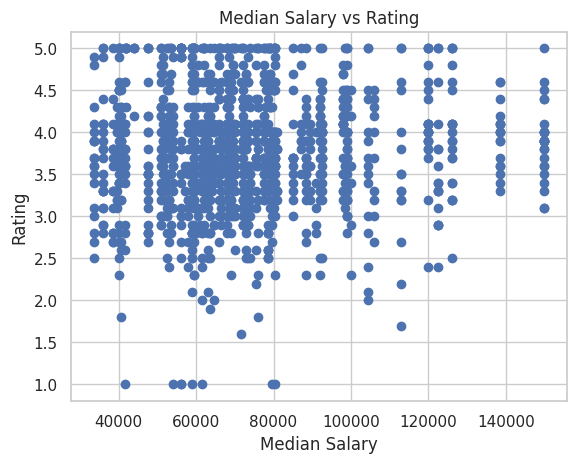

In [479]:
# Check the relationship between the median salary and the rating

plt.scatter(final_df['median_salary'], final_df['rating'])
plt.xlabel('Median Salary')
plt.ylabel('Rating')
plt.title('Median Salary vs Rating')
plt.show()

**Observation:**
- There is no clear relationship between the median salary and company rating as the data shows that companies paying lower salaries can still pull high ratings, and companies paying higher salaries can still plummet to a 1-star rating. There are visible outliers having the lowest rating.

**Data cleaning judgement:**
- Impute the null values by the overall median rating since there are outliers present in the data.



In [480]:
# Calculate the median rating
median_rating = final_df['rating'].median()

# Impute rating null values with the median
final_df['rating'].fillna(median_rating, inplace=True)

/tmp/ipykernel_2515/3623047446.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['rating'].fillna(median_rating, inplace=True)


###### Check the remaining columns with null values.

In [481]:
filter_null(final_df)

,null_counts
ownership_type,186
company_size,146
cleaned_revenue,562
industry,246
sector,246
company_size_group,146


##### Revenue Column

###### Check what variables influence the company revenue to decide whether to use a subset imputation on revenue null values or not on revenue null values.

In [482]:
# Check the relationship of company size and revenue
pd.pivot_table(final_df, index='company_size_group', values='cleaned_revenue', aggfunc=['median', 'mean'])

,median,mean
,cleaned_revenue,cleaned_revenue
company_size_group,,
large,999999999.0,3.187890e+09
medium,24999999.0,7.991279e+07


In [483]:
# Check the relationship between role tier and revenue
pd.pivot_table(final_df, index='role_tier', values='cleaned_revenue', aggfunc='median')

,cleaned_revenue
role_tier,
Junior,499999999.0
Mid,499999999.0
Senior,99999999.0


In [484]:
# Check the relationship between ownerswhip type and revenue
pd.pivot_table(final_df, index=['ownership_type'], values='cleaned_revenue', aggfunc='median')

,cleaned_revenue
ownership_type,
government,5.000000e+08
nonprofit,5.000000e+08
private,1.000000e+08
public,5.000000e+09


##### Company size column

In [485]:
filter_null(final_df)

,null_counts
ownership_type,186
company_size,146
cleaned_revenue,562
industry,246
sector,246
company_size_group,146


In [486]:
# Create a pivot table of median revue by company size
pd.pivot_table(final_df, index='company_size_group', values='cleaned_revenue', aggfunc='median')

,cleaned_revenue
company_size_group,
large,999999999.0
medium,24999999.0


In [487]:
# Filter and display the rows that have NaN values in either 'company_size_group' or 'cleaned_revenue'
final_df[final_df[['company_size_group', 'cleaned_revenue']].isna().any(axis=1)][['cleaned_revenue', 'company_size_group']]

,cleaned_revenue,company_size_group
2,NaN,large
5,NaN,large
7,NaN,large
9,NaN,medium
13,NaN,medium
...,...,...
1531,NaN,NaN
1538,NaN,large
1542,NaN,large
1547,NaN,medium


In [488]:
# Impute the missing clean_revenue values by its median
final_df['cleaned_revenue'].fillna(final_df['cleaned_revenue'].median(), inplace=True)


/tmp/ipykernel_2515/2536894631.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_df['cleaned_revenue'].fillna(final_df['cleaned_revenue'].median(), inplace=True)


###### Impute company size null values by its median

In [489]:
# Calculate the median of revenue
median_revenue = final_df['cleaned_revenue'].median()
median_revenue

99999999.0

In [490]:
# Create a pivote table of median revue by company size
pd.pivot_table(final_df, index='company_size_group', values='cleaned_revenue', aggfunc='median')

,cleaned_revenue
company_size_group,
large,499999999.0
medium,99999999.0


In [491]:
# Create a descriptive statistics for revenue by company size
final_df.groupby('company_size_group')['cleaned_revenue'].describe()


,count,mean,std,min,25%,50%,75%,max
company_size_group,,,,,,,,
large,842.0,2.395747e+09,3.616798e+09,999999.0,99999999.0,499999999.0,5.000000e+09,1.000000e+10
medium,545.0,8.732110e+07,2.552441e+08,999999.0,9999999.0,99999999.0,1.000000e+08,5.000000e+09


In [492]:
# Calculate the 25th and 75th percentiles of revenue for large and medium companies
stats = final_df.groupby('company_size_group')['cleaned_revenue'].describe()

med_25 = stats.loc['medium', '25%']
med_75 = stats.loc['medium', '75%']

large_25 = stats.loc['large', '25%']
large_75 = stats.loc['large', '75%']

# Loop through each row to fill missing company_size_group values based on revenue ranges
for idx, row in final_df.iterrows():
    if pd.isna(row['company_size_group']):
        rev = row['cleaned_revenue']
        if pd.notna(rev):
            if large_25 <= rev <= large_75:
                final_df.at[idx, 'company_size_group'] = 'large'
            elif med_25 <= rev <= med_75:
                final_df.at[idx, 'company_size_group'] = 'medium'

# Display the remaining null counts for company_size_group
final_df['company_size_group'].isna().sum()

np.int64(0)

In [493]:
# Create a table of median number of employees by company size

comp_size_median = final_df[['company_size_group', 'company_size']].groupby('company_size_group').median().reset_index()
comp_size_median

,company_size_group,company_size
0,large,5000.0
1,medium,200.0


In [494]:
# Map the size groups to their respective median sizes from comp_size_median
median_mapping = comp_size_median.set_index('company_size_group')['company_size'].to_dict()

# Loop through rows where company_size is null and fill them using the mapped medians
for index, row in final_df[final_df['company_size'].isna()].iterrows():
    group = row['company_size_group']
    if group in median_mapping:
        final_df.at[index, 'company_size'] = median_mapping[group]

In [495]:
# Check null values
final_df.isna().sum()

,0
cleaned_job_title,0
role_tier,0
min_salary,0
max_salary,0
median_salary,0
company_name,0
ownership_type,186
company_size,0
rating,0
cleaned_revenue,0


##### **Impute categorical missing values**

##### **Categorical Imputation Function**

In [496]:
# Define a list of categorical columns with null values (excluding 'founded' as it is not in final_df)
cols_with_missing_values = ['sector', 'ownership_type', 'industry']

# Create a categorical imputation function to impute null values with its mode
def categorical_imputation(dataframe, cols_with_missing_values):
  for col in cols_with_missing_values:
    dataframe[col] = dataframe[col].fillna(dataframe[col].mode()[0])

# Apply the categorical imputation function
categorical_imputation(final_df, cols_with_missing_values)

In [497]:
rows_after_categorical_imputation = final_df.shape[0]
rows_after_categorical_imputation

1533

In [498]:
# Filter for the remaining columns with null values
filter_null(final_df)

,null_counts


##### 📸 **Data Cleaning Snapshot - Final Data**

In [499]:
# Data Cleaning Snapshot
# Final
nulls_after = final_df.isna().sum()

final_rows, final_cols = final_df.shape


## ✅ Cleaned Data Set Overview

###A. Before

In [500]:
df.head()

,Unnamed: 0,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Founded,Type of ownership,Industry,Sector,Revenue,Competitors,Easy Apply
0,0,"Data Analyst, Center on Immigration and Justic...",$37K-$66K (Glassdoor est.),Are you eager to roll up your sleeves and harn...,3.2,Vera Institute of Justice\n3.2,"New York, NY","New York, NY",201 to 500 employees,1961,Nonprofit Organization,Social Assistance,Non-Profit,$100 to $500 million (USD),-1,True
1,1,Quality Data Analyst,$37K-$66K (Glassdoor est.),Overview\n\nProvides analytical and technical ...,3.8,Visiting Nurse Service of New York\n3.8,"New York, NY","New York, NY",10000+ employees,1893,Nonprofit Organization,Health Care Services & Hospitals,Health Care,$2 to $5 billion (USD),-1,-1
2,2,"Senior Data Analyst, Insights & Analytics Team...",$37K-$66K (Glassdoor est.),We’re looking for a Senior Data Analyst who ha...,3.4,Squarespace\n3.4,"New York, NY","New York, NY",1001 to 5000 employees,2003,Company - Private,Internet,Information Technology,Unknown / Non-Applicable,GoDaddy,-1
3,3,Data Analyst,$37K-$66K (Glassdoor est.),Requisition NumberRR-0001939\nRemote:Yes\nWe c...,4.1,Celerity\n4.1,"New York, NY","McLean, VA",201 to 500 employees,2002,Subsidiary or Business Segment,IT Services,Information Technology,$50 to $100 million (USD),-1,-1
4,4,Reporting Data Analyst,$37K-$66K (Glassdoor est.),ABOUT FANDUEL GROUP\n\nFanDuel Group is a worl...,3.9,FanDuel\n3.9,"New York, NY","New York, NY",501 to 1000 employees,2009,Company - Private,Sports & Recreation,"Arts, Entertainment & Recreation",$100 to $500 million (USD),DraftKings,True


### B. After

In [501]:
final_df.head()

,cleaned_job_title,role_tier,min_salary,max_salary,median_salary,company_name,ownership_type,company_size,rating,cleaned_revenue,...,statistics,tensorflow,docker,git,hadoop,pandas,numpy,company_size_group,state,state_col_tier
0,data analyst center immigration justice cij,Senior,37000,66000,51500,Vera Institute of Justice\n3.2,nonprofit,500.0,3.2,5.000000e+08,...,1,0,0,0,0,0,0,large,New York,High Cost
1,quality data analyst,Senior,37000,66000,51500,Visiting Nurse Service of New York\n3.8,nonprofit,10001.0,3.8,5.000000e+09,...,1,0,0,0,0,0,0,large,New York,High Cost
2,senior data analyst insights analytics team cu...,Senior,37000,66000,51500,Squarespace\n3.4,private,5000.0,3.4,1.000000e+08,...,0,0,0,0,0,0,0,large,New York,High Cost
3,data analyst,Senior,37000,66000,51500,Celerity\n4.1,private,500.0,4.1,1.000000e+08,...,0,0,0,0,0,0,0,large,New York,High Cost
4,reporting data analyst,Senior,37000,66000,51500,FanDuel\n3.9,private,1000.0,3.9,5.000000e+08,...,0,0,0,0,0,0,0,large,New York,High Cost


## 📊 Data Cleaning Results
---
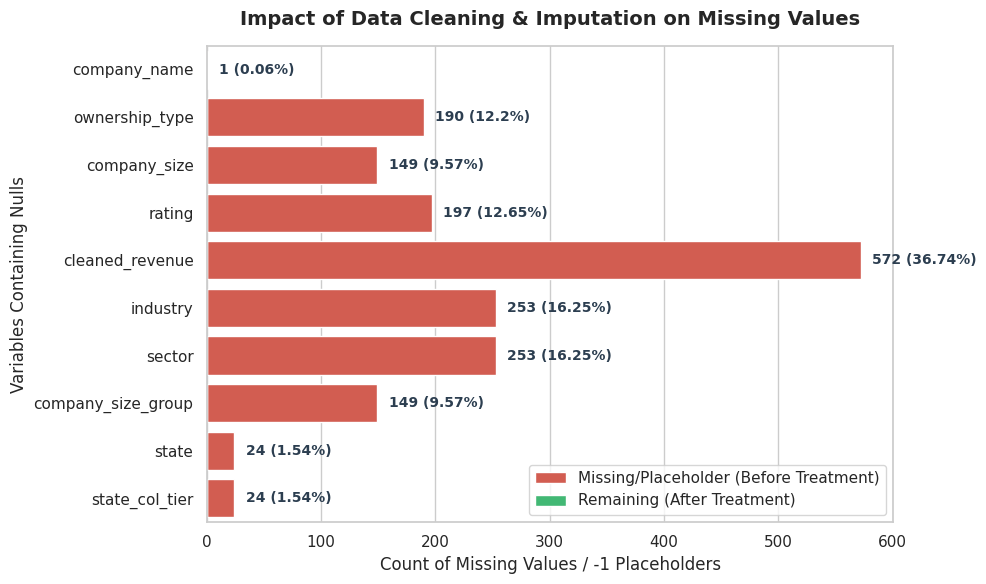

---
## Data Cleaning Results

The cleaning turned the raw postings into a complete, analysis-ready dataset. All missing values and `-1` placeholders were resolved, with no missing values remaining after treatment.

### Dataset Before and After

| Metric | Value |
|---|---|
| Rows in raw dataset | 2,253 |
| Rows after Data Analyst filter | 1,557 |
| Rows dropped (nulls of 5% or less) | 24 |
| **Rows in final dataset** | **1,533** |
| Columns in raw dataset | 16 |
| Columns kept after filtering | 11 |
| New columns engineered | 28 |
| **Columns in final dataset** | **39** |
| `-1` placeholders converted to null | 1,468 |
| Total missing values before treatment | 1,812 |
| **Total missing values after treatment** | **0** |

### Missing Values by Column

| Column | Missing before | Share of rows | Treatment |
|---|---|---|---|
| cleaned_revenue | 572 | 36.74% | Imputed with median by company size group |
| industry | 253 | 16.25% | Imputed with mode |
| sector | 253 | 16.25% | Imputed with mode |
| rating | 197 | 12.65% | Imputed with median |
| ownership_type | 190 | 12.20% | Imputed with mode |
| company_size | 149 | 9.57% | Imputed with median by company size group |
| company_size_group | 149 | 9.57% | Imputed using revenue IQR by size group |
| state | 24 | 1.54% | Rows dropped (5% or less) |
| state_col_tier | 24 | 1.54% | Rows dropped (5% or less) |
| company_name | 1 | 0.06% | Row dropped (5% or less) |

### Key Takeaways
- **Data retained:** 1,533 of the 1,557 Filtered Data Analyst postings (98.5%) were kept, so the cleaning removed very little data.
- **Missing values:** All 1,812 missing or placeholder values were resolved, with revenue needing the most imputation (over a third of postings).
- **Feature growth:** The dataset grew from 11 filtered columns to 39 through 28 engineered features, including role tier, skills, state, cost of living, company size group, and binary columns.
- **Readiness:** The data is consistent, numeric where needed, and ready for the exploratory data analysis.


In [502]:
summary = pd.DataFrame({
    "Metric": [
        "Rows in raw dataset",
        "Rows after Data Analyst filter",
        "Rows dropped (nulls < 5%)",
        "Rows in final dataset",
        "Columns in raw dataset",
        "Filtered Columns",
        "New columns engineered",
        "Columns in final dataset",
        "-1 placeholders converted to null",
        "Total missing values before treatment",
        "Total missing values after treatment",
    ],
    "Value": [
        raw_rows,
        rows_after_filter,
        rows_before_drop - rows_after_drop,
        final_rows,
        raw_cols,
        selected_cols,
        final_cols - selected_cols,
        final_cols,
        int(placeholder_counts.sum()),
        int(nulls_before.sum()),
        int(nulls_after.sum()),
    ],
})
summary

,Metric,Value
0,Rows in raw dataset,2253
1,Rows after Data Analyst filter,1557
2,Rows dropped (nulls < 5%),24
3,Rows in final dataset,1533
4,Columns in raw dataset,16
5,Filtered Columns,11
6,New columns engineered,28
7,Columns in final dataset,39
8,-1 placeholders converted to null,1468
9,Total missing values before treatment,1812


In [503]:
print(f"Data retained: {final_rows / raw_rows:.1%}")

Data retained: 68.0%


In [504]:
missing_report = pd.DataFrame({
    "missing_before": nulls_before,
    "pct_before": (nulls_before / rows_before_drop * 100).round(2).astype(str) + "%",
    "missing_after": nulls_after,
}).query("missing_before > 0")

missing_report

,missing_before,pct_before,missing_after
company_name,1,0.06%,0
ownership_type,190,12.2%,0
company_size,149,9.57%,0
rating,197,12.65%,0
cleaned_revenue,572,36.74%,0
industry,253,16.25%,0
sector,253,16.25%,0
company_size_group,149,9.57%,0
state,24,1.54%,0
state_col_tier,24,1.54%,0


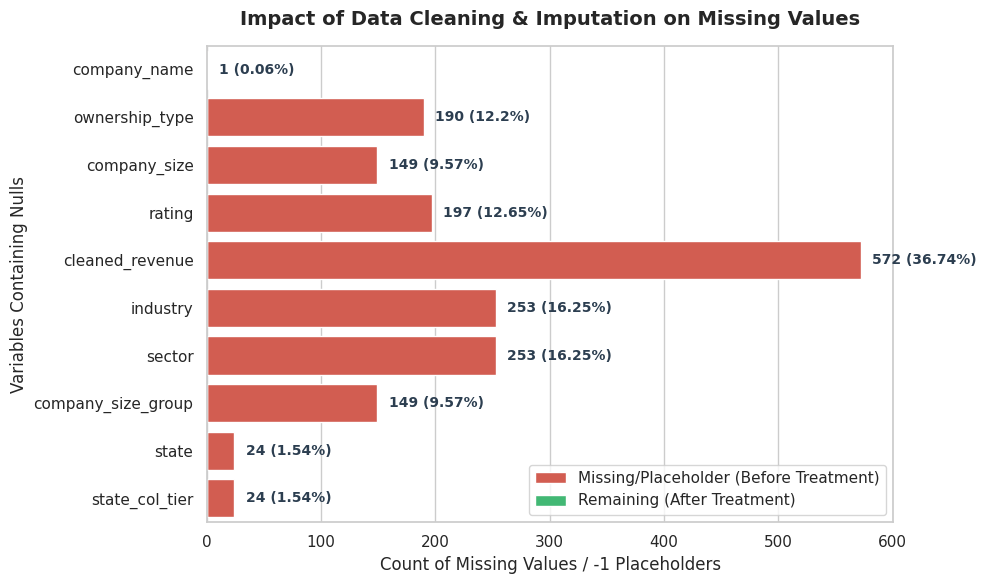

In [505]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Prepare data for plotting
plot_data = missing_report.reset_index().rename(columns={"index": "Variable"})

# Set figure size
plt.figure(figsize=(10, 6))

# Plot missing values before
sns.barplot(
    x="missing_before",
    y="Variable",
    data=plot_data,
    color="#e74c3c",
    label="Missing/Placeholder (Before Treatment)"
)

# Plot missing values after
sns.barplot(
    x="missing_after",
    y="Variable",
    data=plot_data,
    color="#2ecc71",
    label="Remaining (After Treatment)"
)

# Add details and styling
plt.title("Impact of Data Cleaning & Imputation on Missing Values", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Count of Missing Values / -1 Placeholders", fontsize=12)
plt.ylabel("Variables Containing Nulls", fontsize=12)
plt.legend(loc="lower right", frameon=True)

# Annotate the original missing counts on the bars
for i, row in plot_data.iterrows():
    plt.text(
        row["missing_before"] + 10,
        i,
        f"{int(row['missing_before'])} ({row['pct_before']})",
        va="center",
        fontsize=10,
        color="#2c3e50",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

##  📥 Download the Cleaned Dataset

In [506]:
#Convert the dataframe to a csv file
final_df.to_csv('glassdoor_jobs_cleaned.csv', index=False)

#Download the csv file
from google.colab import files
files.download('glassdoor_jobs_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>